In [2]:
# importing libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# loading import data
df=sns.load_dataset('tips')

In [4]:
df.head(4)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2


In [5]:
df.shape

(244, 7)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [7]:
df.corr(numeric_only=True)

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


<Axes: >

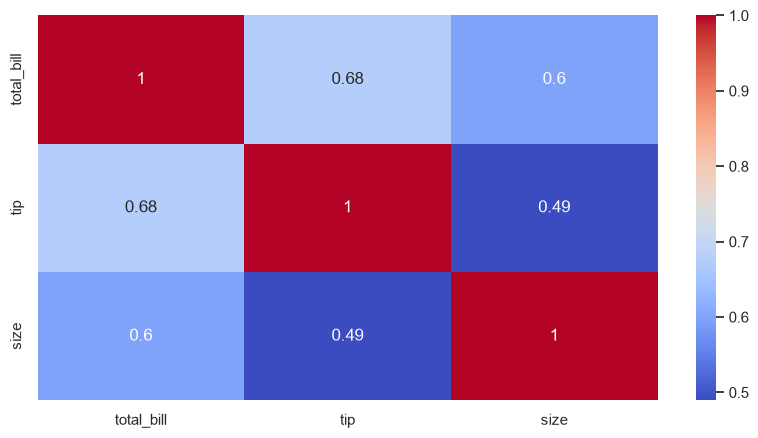

In [8]:
# Heatmap For Correlation 
sns.set(rc={'figure.figsize':(10,5)})
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')

In [9]:
# Check for duplicated value
df.duplicated().value_counts()

False    243
True       1
Name: count, dtype: int64

In [10]:
# Drop the duplicated data
df=df.drop_duplicates()

In [11]:
df.describe()

,total_bill,tip,size
count,243.000000,243.000000,243.000000
mean,19.813868,3.002387,2.572016
std,8.910071,1.385002,0.952356
min,3.070000,1.000000,1.000000
25%,13.380000,2.000000,2.000000
50%,17.810000,2.920000,2.000000
75%,24.175000,3.575000,3.000000
max,50.810000,10.000000,6.000000


In [12]:
# checking for the missing values
df.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

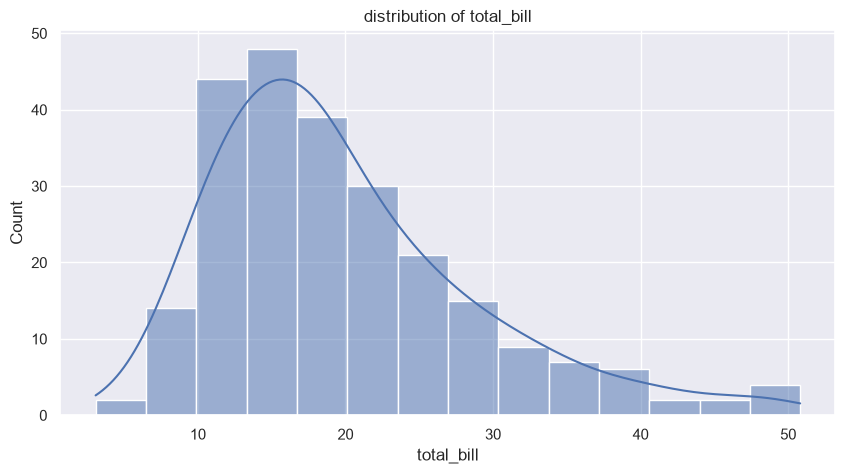

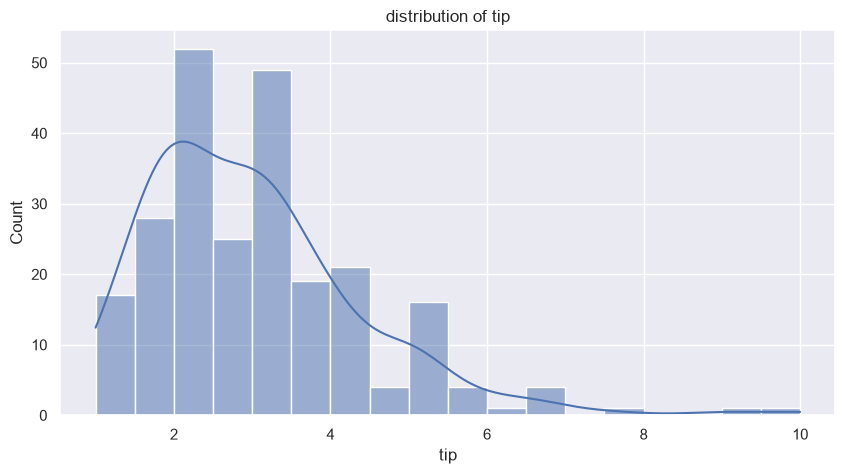

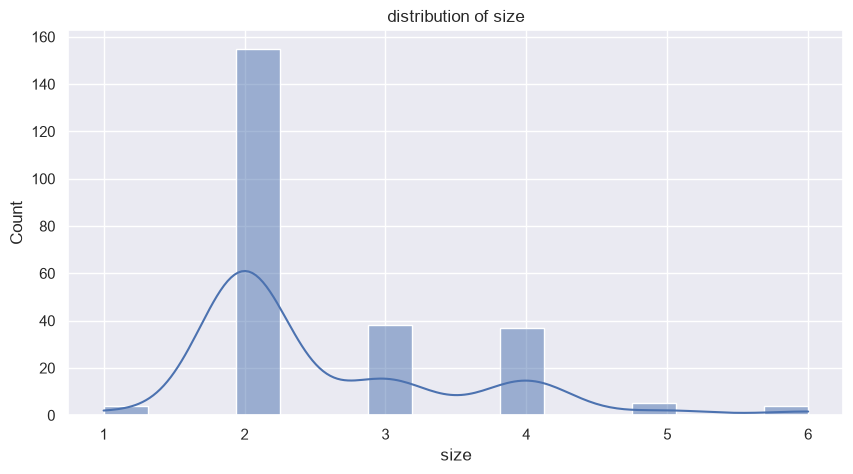

In [13]:
# # Univarite  Analysis-distribution shape,spread,skew for the numeric values
numeric_cols=['total_bill','tip','size']
for col in numeric_cols:
    plt.figure()
    sns.histplot(df[col],kde=True)
    plt.title(f'distribution of {col}')
    plt.show()


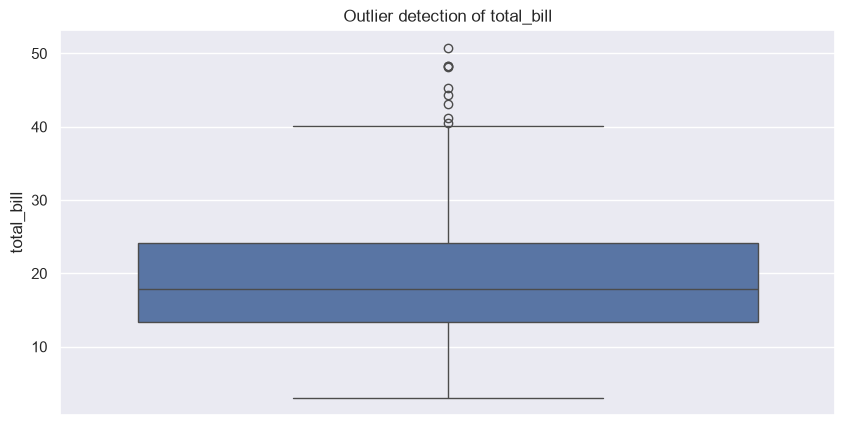

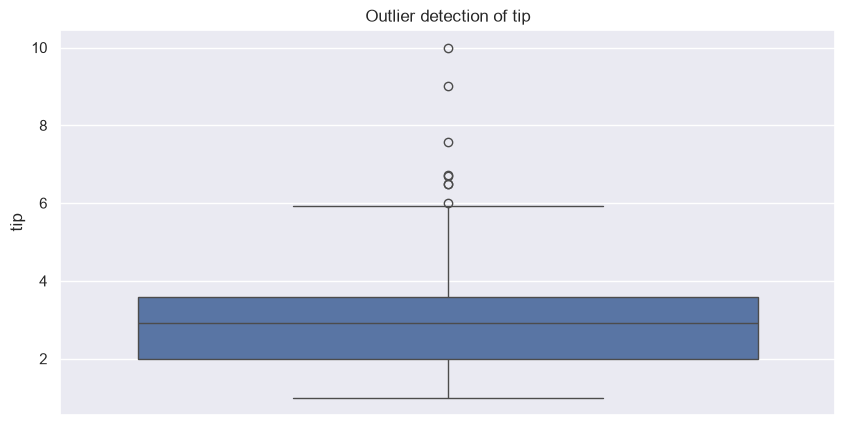

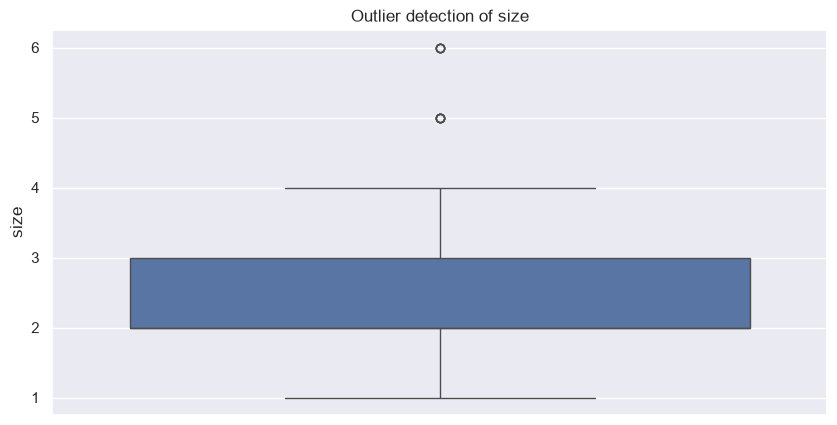

In [14]:
# Outlier detection using the box plot
for col in numeric_cols:
    sns.boxplot(df[col])
    plt.title(f'Outlier detection of {col}')
    plt.show()

In [15]:
# Outlier handling
def cap_outliers(df,col):
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    df[col]=df[col].clip(lower=lower,upper=upper)
    return df
for col in ['total_bill','tip','size']:
    df=cap_outliers(df,col)
print(df.shape)
    

(243, 7)


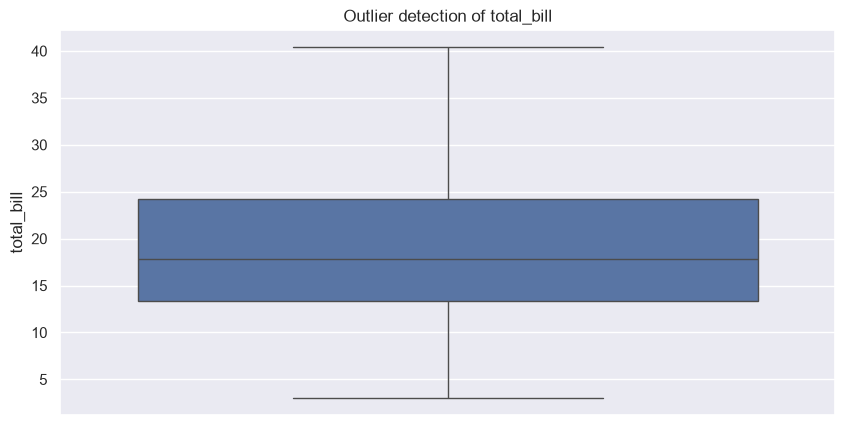

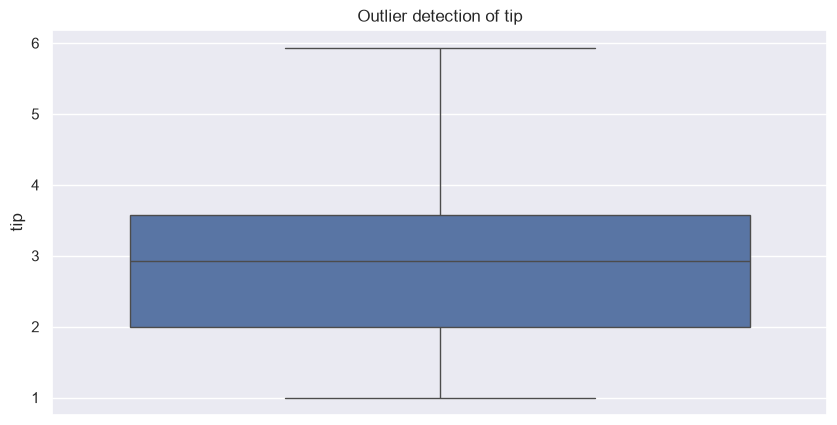

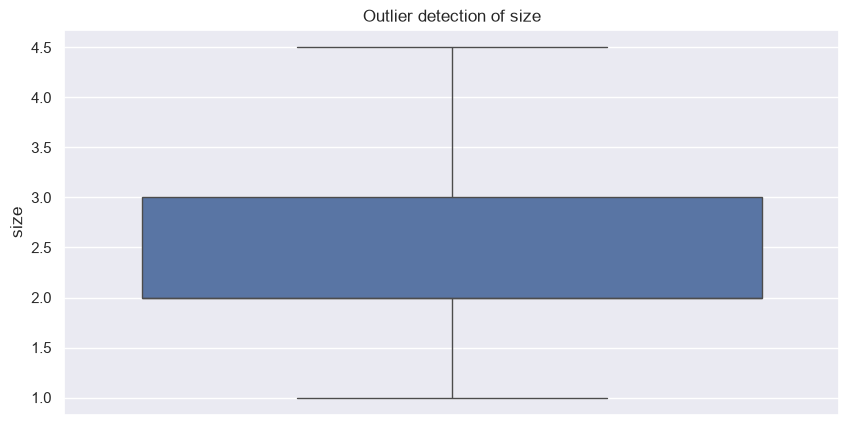

In [16]:
# Checking outlier handle or not
for col in numeric_cols:
    sns.boxplot(df[col])
    plt.title(f'Outlier detection of {col}')
    plt.show()

In [17]:
df.head(3)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2.0
1,10.34,1.66,Male,No,Sun,Dinner,3.0
2,21.01,3.50,Male,No,Sun,Dinner,3.0


In [41]:
df.shape

(243, 7)

<Axes: xlabel='day', ylabel='smoker'>

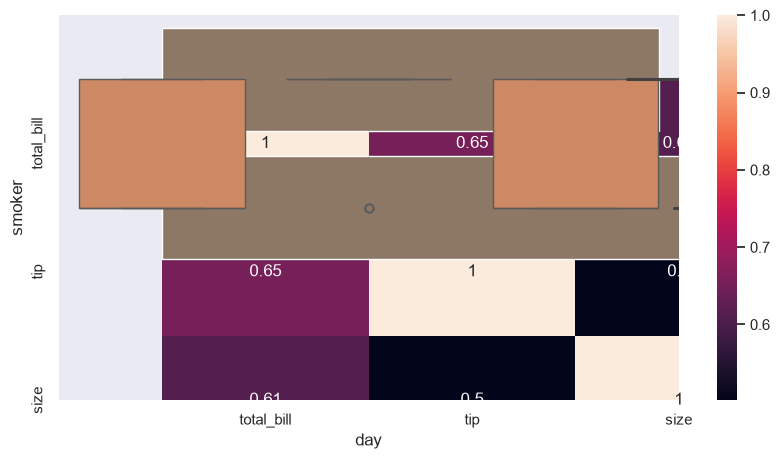

In [18]:

sns.scatterplot(x='total_bill', y='tip', data=df)
df[['total_bill','tip','size']].corr()
sns.heatmap(df[['total_bill','tip','size']].corr(), annot=True)

# Categorical vs numeric (target)
sns.boxplot(x='day', y='smoker', data=df)
sns.boxplot(x='sex', y='smoker', data=df)
sns.boxplot(x='total_bill', y='smoker', data=df)
sns.boxplot(x='time', y='smoker', data=df)
sns.barplot(x='size', y='smoker', data=df)

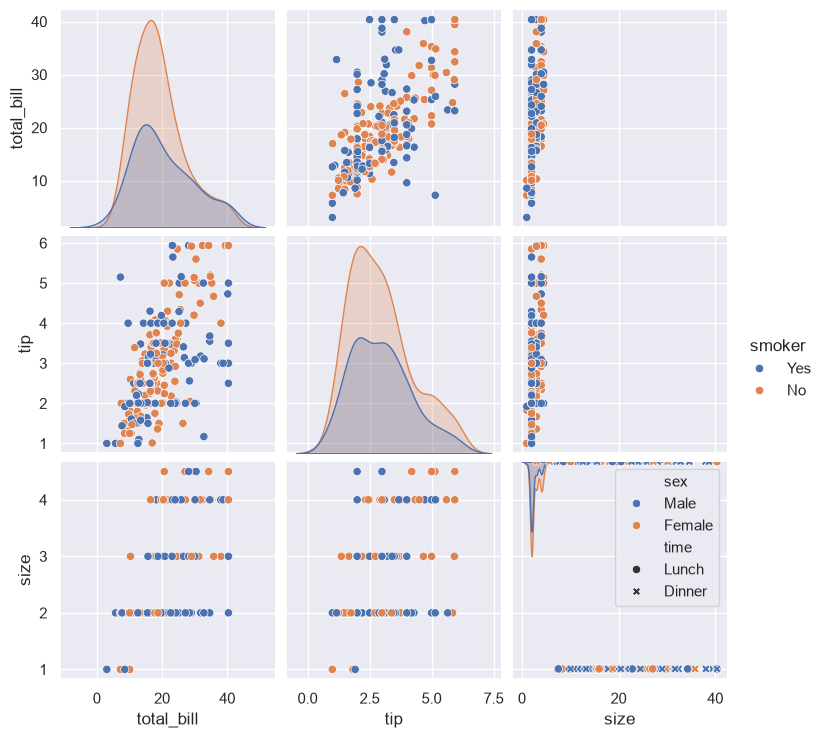

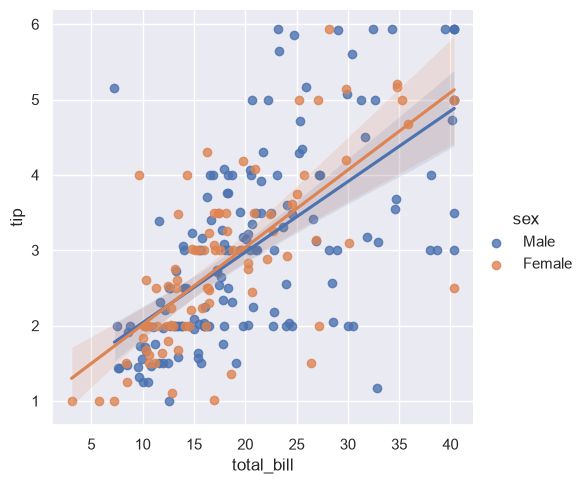

In [19]:
sns.pairplot(df, hue='smoker')       # or hue='sex', 'time'
sns.scatterplot(x='total_bill', y='smoker', hue='sex', style='time', data=df)
sns.lmplot(x='total_bill', y='tip', hue='sex', data=df)

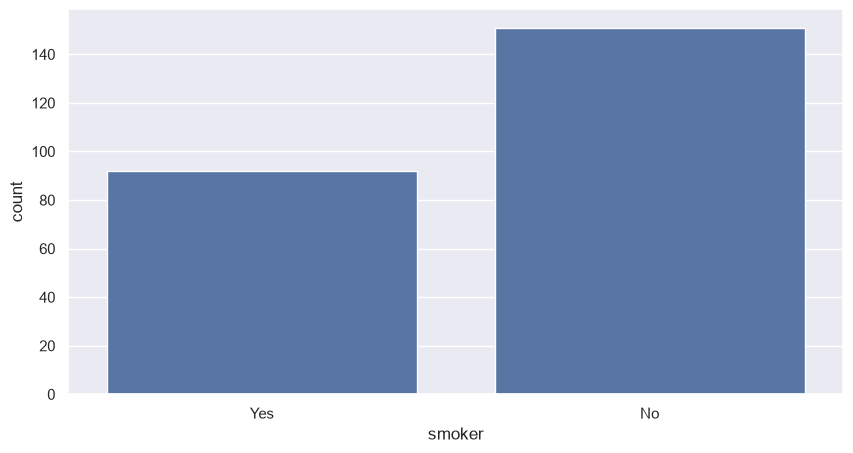

In [20]:
sns.countplot(data=df,x='smoker')
plt.show()

In [40]:
df.shape

(243, 7)

In [22]:
df.describe()

,total_bill,tip,size
count,243.000000,243.000000,243.000000
mean,19.621389,2.955021,2.537037
std,8.365671,1.229247,0.853207
min,3.070000,1.000000,1.000000
25%,13.380000,2.000000,2.000000
50%,17.810000,2.920000,2.000000
75%,24.175000,3.575000,3.000000
max,40.367500,5.937500,4.500000


In [23]:
df.head(3)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2.0
1,10.34,1.66,Male,No,Sun,Dinner,3.0
2,21.01,3.50,Male,No,Sun,Dinner,3.0


In [24]:
# Divide the data into X and y
X=df.drop(columns='smoker')
y=df['smoker']

# Encoding

In [25]:
df['time'].value_counts()

time
Dinner    176
Lunch      67
Name: count, dtype: int64

In [26]:
df['day'].value_counts()

day
Sat     87
Sun     76
Thur    61
Fri     19
Name: count, dtype: int64

In [27]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y=le.fit_transform(y)

    

In [28]:
print(le.classes_)
print(y[:10])

['No' 'Yes']
[0 0 0 0 0 0 0 0 0 0]


In [29]:
X.head()

,total_bill,tip,sex,day,time,size
0,16.99,1.01,Female,Sun,Dinner,2.0
1,10.34,1.66,Male,Sun,Dinner,3.0
2,21.01,3.50,Male,Sun,Dinner,3.0
3,23.68,3.31,Male,Sun,Dinner,2.0
4,24.59,3.61,Female,Sun,Dinner,4.0


In [30]:
# Encode the categorical columns
X=pd.get_dummies(X,columns=['sex','day','time'],drop_first=True,dtype=int)

In [31]:
X.head(10)

,total_bill,tip,size,sex_Female,day_Fri,day_Sat,day_Sun,time_Dinner
0,16.99,1.01,2.0,1,0,0,1,1
1,10.34,1.66,3.0,0,0,0,1,1
2,21.01,3.50,3.0,0,0,0,1,1
3,23.68,3.31,2.0,0,0,0,1,1
4,24.59,3.61,4.0,1,0,0,1,1
5,25.29,4.71,4.0,0,0,0,1,1
6,8.77,2.00,2.0,0,0,0,1,1
7,26.88,3.12,4.0,0,0,0,1,1
8,15.04,1.96,2.0,0,0,0,1,1
9,14.78,3.23,2.0,0,0,0,1,1


In [44]:
df.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  243 non-null    float64 
 1   tip         243 non-null    float64 
 2   sex         243 non-null    category
 3   smoker      243 non-null    category
 4   day         243 non-null    category
 5   time        243 non-null    category
 6   size        243 non-null    float64 
dtypes: category(4), float64(3)
memory usage: 9.1 KB


# Scale the data


In [47]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
float_cols=['total_bill','tip','size']

df[float_cols]=scaler.fit_transform(df[float_cols])

In [48]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# Model selection 

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [50]:
models={
    'Logistic Regression':LogisticRegression(max_iter=1000),
    'Decision Tree Classifier':DecisionTreeClassifier(),
    'Random Forest Classifier':RandomForestClassifier(),
    'K-Neighbors Classifier':KNeighborsClassifier(),
    'Support vector Machine':SVC()

}

In [51]:
for name, model in models.items():
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)


In [52]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [53]:
# Start training and model evaluation
for name,model in models.items():
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    print(f"model:{name}\t Accuracy_score:{accuracy_score(y_test,y_pred)*100}")

model:Logistic Regression	 Accuracy_score:75.51020408163265
model:Decision Tree Classifier	 Accuracy_score:63.26530612244898
model:Random Forest Classifier	 Accuracy_score:69.38775510204081
model:K-Neighbors Classifier	 Accuracy_score:73.46938775510205
model:Support vector Machine	 Accuracy_score:75.51020408163265
